# Set 12: EDA + Random Forest (4 models)

**Q1 → Exp 1A / 1B** · **Q2 → Exp 10** (Random Forest)

Datasets: Q1 `Diabetes.csv`. Q2 asks for `house_price.csv`, which we don't have, so this uses **`Diabetes.csv`**. If your house file has a numeric price, make 2 classes first: `df["Class"] = (df["Price"] > df["Price"].median()).astype(int)`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Q1.2 Display the outlier values of numerical columns using Z-score

In [3]:
num = df.select_dtypes("number")
z = ((num - num.mean()) / num.std()).abs()      # z-score: how many std-devs each value is from its column mean
for col in num.columns:
    outliers = num[col][z[col] > 3]
    print(f"{col}: {len(outliers)} outliers ->", outliers.values[:10])

Pregnancies: 4 outliers -> [15 17 14 14]
Glucose: 5 outliers -> [0 0 0 0 0]
BloodPressure: 35 outliers -> [0 0 0 0 0 0 0 0 0 0]
SkinThickness: 1 outliers -> [99]
Insulin: 18 outliers -> [543 846 495 485 495 478 744 680 545 465]
BMI: 14 outliers -> [ 0.   0.   0.   0.   0.  67.1  0.   0.  59.4  0. ]
DiabetesPedigreeFunction: 11 outliers -> [2.288 1.893 1.781 2.329 1.476 2.137 1.731 1.6   2.42  1.699]
Age: 5 outliers -> [69 72 81 70 69]
Outcome: 0 outliers -> []


### Q1.3 Bivariate analysis: continuous vs categorical (categorical plot)

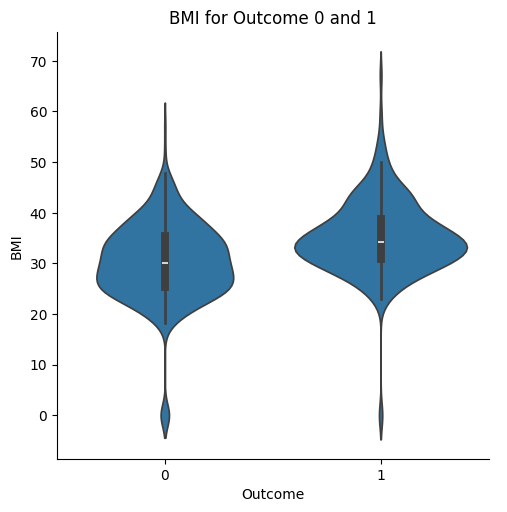

In [4]:
sns.catplot(x="Outcome", y="BMI", data=df, kind="violin")
plt.title("BMI for Outcome 0 and 1")
plt.show()

### Q1.4 Mode imputation for categorical data if missing > 10%

In [5]:
pct = df.isnull().mean() * 100                      # % missing in every column
for col in ["Outcome"]:
    if pct[col] > 10:
        df[col] = df[col].fillna(df[col].mode()[0])
        print(f"{col}: {pct[col]:.1f}% missing -> filled with mode")
    else:
        print(f"{col}: {pct[col]:.1f}% missing -> not more than 10%, left as it is")

Outcome: 0.0% missing -> not more than 10%, left as it is


Outcome is the only categorical column, and it has no missing values. The same loop fills any categorical column that's above 10%.

### Q1.5 Z-score normalisation of a numerical feature, analysed with a scatter plot

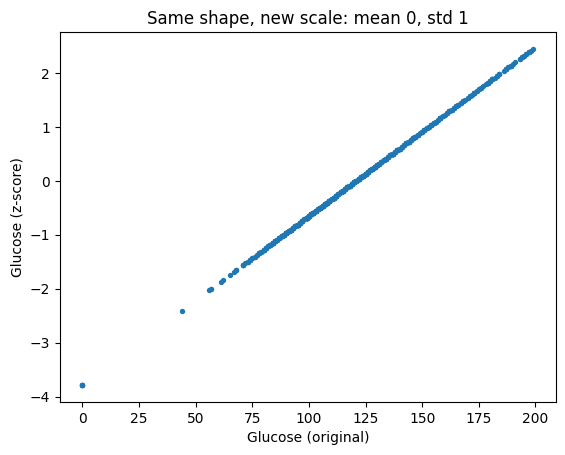

In [6]:
col = "Glucose"
df[col + "_z"] = (df[col] - df[col].mean()) / df[col].std()
plt.scatter(df[col], df[col + "_z"], s=8)
plt.xlabel(col + " (original)")
plt.ylabel(col + " (z-score)")
plt.title("Same shape, new scale: mean 0, std 1")
plt.show()

---
## Question 2

### Q2.1 Read the dataset and preprocess
### Q2.2 Choose X (independent) and Y (dependent)

*One code cell below answers both parts.*

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/Diabetes.csv")
zero_is_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]   # a 0 here is impossible = missing
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)
df = df.fillna(df.median())                           # fill with the median
X = StandardScaler().fit_transform(df.drop(columns="Outcome"))
y = df["Outcome"]
print(X.shape, y.value_counts().to_dict())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

(768, 8) {0: 500, 1: 268}
Train: (576, 8)  Test: (192, 8)


### Q2.3 Four Random Forest models with different parameters
### Q2.5 Confusion table, accuracy, precision, recall and F-score for each

*One code cell below answers both parts.*

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

params = [dict(n_estimators=10, max_depth=None), dict(n_estimators=50, max_depth=5),
          dict(n_estimators=100, criterion="entropy"), dict(n_estimators=200, max_depth=8, min_samples_leaf=2)]
rows = []
for p in params:
    pred = RandomForestClassifier(random_state=42, **p).fit(X_train, y_train).predict(X_test)
    print(p, "\n", confusion_matrix(y_test, pred))
    rows.append([str(p), accuracy_score(y_test, pred), precision_score(y_test, pred, average="macro"),
                 recall_score(y_test, pred, average="macro"), f1_score(y_test, pred, average="macro")])
pd.DataFrame(rows, columns=["Parameters", "Accuracy", "Precision", "Recall", "F-score"]).round(4)

{'n_estimators': 10, 'max_depth': None} 
 [[94 29]
 [28 41]]
{'n_estimators': 50, 'max_depth': 5} 
 [[98 25]
 [25 44]]
{'n_estimators': 100, 'criterion': 'entropy'} 
 [[97 26]
 [21 48]]
{'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 2} 
 [[100  23]
 [ 22  47]]


,Parameters,Accuracy,Precision,Recall,F-score
0,"{'n_estimators': 10, 'max_depth': None}",0.7031,0.6781,0.6792,0.6786
1,"{'n_estimators': 50, 'max_depth': 5}",0.7396,0.7172,0.7172,0.7172
2,"{'n_estimators': 100, 'criterion': 'entropy'}",0.7552,0.7353,0.7421,0.7382
3,"{'n_estimators': 200, 'max_depth': 8, 'min_sam...",0.7656,0.7456,0.7471,0.7463


### Q2.4 Find the best parameters and calculate Y_predict

In [9]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(RandomForestClassifier(random_state=42),
                      {"n_estimators": [50, 100, 200], "max_depth": [None, 5, 8]}, cv=5, n_jobs=-1).fit(X_train, y_train)
print("Best parameters:", search.best_params_)
y_pred = search.predict(X_test)
print("Y_predict:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Best parameters: {'max_depth': 8, 'n_estimators': 50}
Y_predict: [1 0 0 0 1 1 0 1 1 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 0 0 0 0 0 1 0 0 1 1 0 0 1 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0
 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 0
 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 0 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 1 1 1 0 1 0 1 0 0 0 0 1 0 0 0 1 1
 0 0 0 1 1 0 0]
Accuracy: 0.7396
